In [20]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk3-task2-spills.ipynb")

# Task 2: Visualizing oil spills in NY State

## Instructions

- First, update the following cell to have a link to *your* Homework 3 GitHub repository:

**UPDATE THIS LINK**
https://github.com/sarah-busby/eds220-hwk3


- Review the [complete rubric for this task](https://docs.google.com/document/d/1Ce4EO3MEHW5uLks4x8BECWlkim2bcmxB4f8Qo4z26z8/edit?usp=sharing) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- Comment mindfully in a way that enriches your code. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.


## About the data
In this task you will use two datasets:

### First dataset: oil spills data

The first dataset contains information about [spilling incidents in the state of New York](https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk). Make sure you study the data portal and understand what each row represents before starting to code. 
You will find extra information and metadata for this dataset in the `NYSDEC_SpillIncidents_Overview.pdf` and `NYSDEC_SpillIncidents_DataDictionary.pdf` documents available at the portal.

### Second dataset: TIGER shapefile

The second dataset is the [2026 Counties (and equivalent) TIGER shapefile](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html) (file `tl_2026_us_county.zip`) from the Census Bureau. You can check the [metadata for all the TIGER shapefiles here](https://www.census.gov/programs-surveys/geography/technical-documentation/complete-technical-documentation/tiger-geo-line.html). 

### COMPLETE WORKFLOW
You will use the next code cell to complete the last exercise in the task. Leave it blank for now.

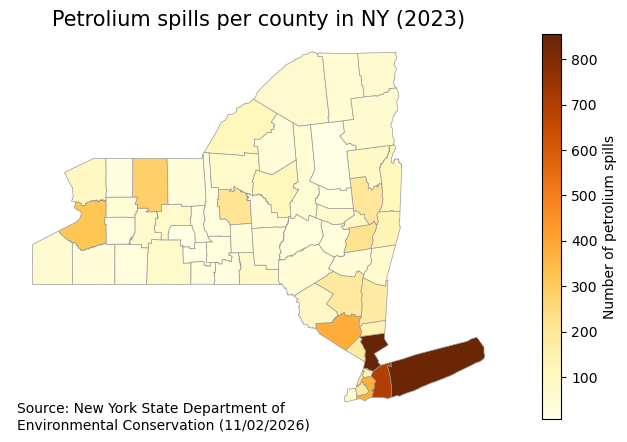

In [2]:
# FINAL CODE

# Import libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

# Read in data

# Read in NY spill incident data
fp = os.path.join('data', 'Spill_Incidents.csv')
spills = pd.read_csv(fp)

# Read in counties data
fp = os.path.join('data', 'tl_2026_us_county', 'tl_2026_us_county.shp')
counties = gpd.read_file(fp)

# Clean `spills` dataframe

# Simplify `spills` column names
spills.columns = spills.columns.str.lower().str.replace(' ','_')

# Update 'quantity' column to float
spills['quantity'] = spills['quantity'].str.replace(',', '').astype(float)

# Update `spill_date` to datetime
spills['spill_date'] = pd.to_datetime(spills['spill_date'], format='%m/%d/%Y')

# Clean `counties` dataframe

# Transform column names to lowercawse
counties.columns = counties.columns.str.lower()

# Rename column `name` to `county
counties = counties.rename(columns={'name':'county'})


# Summarize number of petroleum spills by county in 2023
spills_per_county = (spills[(spills['spill_date'].between("2023-01-01", "2023-12-31")) & # Select spills from 2023 
                            (spills['material_family'] == "Petroleum")]                  # Select petroleum spills
                     .groupby('county')['spill_number'].nunique().reset_index()          # Count spills by county
                     .rename(columns={'spill_number':'n_spills'})                        # Rename number of spills col
                    )

# Rename `St Lawrence` county to `St. Lawrence`
spills_per_county.iloc[52,0] = 'St. Lawrence'

# Select counties in New York state
ny_counties = counties[counties['statefp'] == '36'] # state FIP code for NY = 36 from metadata

# Combine spills per county with NY counties
ny_spills = ny_counties.merge(spills_per_county, on='county')

# Add Tuscarora Indian Reserve spills to Niagra county count
ny_spills.at[1, 'n_spills'] = ny_spills.at[1, 'n_spills'] + spills_per_county.loc[58,'n_spills']

# Add Onondaga Indian Reservation spill to Onondaga county count
ny_spills.at[19, 'n_spills'] = ny_spills.at[19, 'n_spills'] + spills_per_county.loc[35,'n_spills']


# Plot petrolium spills per county in NY
fig, ax = plt.subplots(figsize=(9, 5))

# Remove axis
ax.axis('off')

# Title for the plot
ax.set_title('Petrolium spills per county in NY (2023)', 
              fontsize=15)

# Add oil spill by county
ny_spills.plot(ax=ax,
               column = 'n_spills',
               cmap = 'YlOrBr',
               edgecolor="0.6",
               linewidth=0.5,
               legend = True,
               legend_kwds={'label': 'Number of petrolium spills'}
              )

# Add caption
plt.figtext(0.2, 0.095,
            'Source: New York State Department of \nEnvironmental Conservation (11/02/2026)',
            horizontalalignment = 'left',
            wrap = True
           )

plt.show();

## 1. File management
a. Any data you download should go in the `data/` folder of your `eds220-hwk3` repository. For example, after downloading both datasets, your repository should look like this:

```
eds220-hwk3/
├── data/
│   ├── q5d_df.csv
│   ├── Spill_Incidents_20261027.csv
│   └── tl_2026_us_county/
│       ├── tl_2026_us_county.cpg
│       ├── tl_2026_us_county.dbf
│       ├── tl_2026_us_county.prj
│       ├── tl_2026_us_county.shp
│       └── ... (other files from the shapefile)
├── tests/
├── .gitignore
├── LICENSE
├── README.md
└── hwk3-task2-spills.ipynb
```

The date in the name of the spills file may be different, depending on when you download it. `data/q5d_df.csv` is already in the repository and is used by the autograder tests, so do not delete or move it.

**IMPORTANT: Do not commit your data!**

The datasets we'll be working with are large and will most likely jam your commit history if git does not ignore them.

b. Add the relative path of each dataset you downloaded to your `.gitignore` file. For example, to ignore the folder containing the shapefile, add `data/tl_2026_us_county/` to the `.gitignore`.

c. Commit and push your changes to the `.gitignore`.

d. Run `git status` and verify that none of your data is being tracked by git.

## 2. Datasets description
- Read the metadata for both datasets and write a brief description about each one. Indicate the data sources and date of access.

### NY oil spills data
- This dataset is published by the New York State Department of Environmental Conservation and contains information about hazardous material spills across the state. Information about the spills include time and location of spill, the material family and name of the material spilled, and how much was spilled and recovered.
- **Source:** https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk/about_data
- **Date accessed:** 11/2/2026

### 2026 TIGER shapefiles: Counties and equivalent
- This dataset from the United States Census Bureau contains the shapefiles of the legal county (and equivalent) boundaries and their names in the United States. Other information included are state, county, and other Federal Information Processing Standards (FIPS) codes to link the county to other federal datasets.
- **Source:** https://www.census.gov/cgi-bin/geo/shapefiles/index.php?year=2026&layergroup=Counties+%28and+equivalent%29
- **Date accessed:** 11/2/2026

## 3. Import libraries

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

## 4. Import data 
In the next cell:

- Import the NY spills data as a variable named `spills`. 
- Import the US counties data as a variable named `counties`.

If you are using file paths to access the data, these should be constructed using the `os` package.

In [4]:
fp = os.path.join('data', 'Spill_Incidents.csv')
spills = pd.read_csv(fp)

fp = os.path.join('data', 'tl_2026_us_county', 'tl_2026_us_county.shp')
counties = gpd.read_file(fp)

<!-- BEGIN QUESTION -->

## 5. Prepare spills data

This section refers to the `spills` dataframe. 
Check the outputs carefully, they will give you information you will need to use in the next exercises.

### 5.A. Exploration

In the next cells:

a. Check the dataframe's head

b. Check the data types of the columns

c. Check the unique values in the `material_family` column

d. Check the unique values in the `county` column

e. Insert a markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells for preliminary data exploration.

From the preliminary exploration, I found that the majority of column values were read in as strings, including "date" and "quantity" columns. The `Material Family` column looks clean with 4 unique values. Also, looking through the `county` column, the dataset appears to contains spills from areas outside of New York like Canada and Pennsylvania. This makes sense as spills in these neighboring areas would affect New York State.

In [5]:
#a. Check the dataframe's head
spills.head()

,Spill Number,Program Facility Name,Street 1,Street 2,Locality,County,ZIP Code,SWIS Code,DEC Region,Spill Date,Received Date,Contributing Factor,Waterbody,Source,Close Date,Material Name,Material Family,Quantity,Units,Recovered
0,107132,MH 864,RT 119/MILLWOOD RD,NaN,ELMSFORD,Westchester,NaN,6000,3,10/10/2001,10/10/2001,Unknown,NaN,Unknown,10/15/2001,unknown material,Other,10,Gallons,0
1,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,NaN,0
2,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,Pounds,0
3,204667,POLE 16091,GRACE AVE/BURKE AVE,NaN,BRONX,Bronx,NaN,301,2,08/02/2002,08/02/2002,Equipment Failure,NaN,Commercial/Industrial,10/28/2002,transformer oil,Petroleum,1,Gallons,0
4,210559,POLE ON,FERDALE LOMIS RD / RT 52,NaN,LIBERTY,Sullivan,NaN,5336,3,01/20/2003,01/20/2003,Traffic Accident,NaN,Commercial/Industrial,01/22/2003,transformer oil,Petroleum,6,Gallons,6


In [6]:
#b. Check the data types of the columns
print(spills.dtypes)

Spill Number              int64
Program Facility Name    object
Street 1                 object
Street 2                 object
Locality                 object
County                   object
ZIP Code                 object
SWIS Code                 int64
DEC Region                int64
Spill Date               object
Received Date            object
Contributing Factor      object
Waterbody                object
Source                   object
Close Date               object
Material Name            object
Material Family          object
Quantity                 object
Units                    object
Recovered                object
dtype: object


In [7]:
#c. Check the unique values in the `material_family` column
spills['Material Family'].unique()

array(['Other', 'Petroleum', 'Hazardous Material', 'Oxygenates'],
      dtype=object)

In [8]:
#d. Check the unique values in the `county` column
spills['County'].unique()

array(['Westchester', 'Queens', 'Bronx', 'Sullivan', 'Cortland',
       'New York', 'Ulster', 'Kings', 'Orange', 'Dutchess', 'Onondaga',
       'Saratoga', 'Cayuga', 'Oswego', 'Warren', 'Niagara', 'Rockland',
       'Nassau', 'Jefferson', 'Schenectady', 'Albany', 'Monroe',
       'Schuyler', 'St Lawrence', 'Richmond', 'Clinton', 'Lewis', 'Essex',
       'Chenango', 'Erie', 'Livingston', 'Oneida', 'Wayne', 'Suffolk',
       'Orleans', 'Ontario', 'Genesee', 'Otsego', 'Tompkins', 'Madison',
       'Chemung', 'Seneca', 'Broome', 'Hamilton', 'Washington', 'Steuben',
       'Rensselaer', 'Franklin', 'Columbia', 'Fulton', 'Herkimer',
       'Schoharie', 'Montgomery', 'Putnam', 'Delaware',
       'New Jersey - Region 2', 'Tioga', 'Chautauqua', 'Cattaraugus',
       'Wyoming', 'Yates', 'Greene', 'Pennsylvania - Region 9',
       'Allegany', 'New Jersey - Region 3 (N)',
       'Cattaraugus Indian Reservation', 'Connecticut - Region 3 (T)',
       'New Jersey - Region 3 (T)', 'Canada - Region 6',

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.B. Cleaning
a. Simplify column names as needed.

In [9]:
# Simplify column names to snake case
spills.columns = spills.columns.str.lower().str.replace(' ','_')

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Update column data types as needed.

In [10]:
# Update date columns to datetime
spills['spill_date'] = pd.to_datetime(spills['spill_date'], format='%m/%d/%Y')

spills['received_date'] = pd.to_datetime(spills['received_date'], format='%m/%d/%Y')

spills['close_date'] = pd.to_datetime(spills['close_date'], format='%m/%d/%Y')

In [11]:
# Update 'quantity' and 'recovered' columns to floats
spills['quantity'] = spills['quantity'].str.replace(',', '').astype(float)

spills['recovered'] = spills['recovered'].str.replace(',', '').astype(float)

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.C. Data selection

a. Select data about petroleum spills that took place between January 1 and December 31, 2023 (including both dates). Store it in a variable named `petr_23`. The data selection should occur in a single line. You may add cells as needed.

In [12]:
# Select petroleum spills in 2023
petr_23 = spills[(spills['spill_date'].between("2023-01-01", "2023-12-31")) & (spills['material_family'] == "Petroleum")]

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use `print()` and f-strings to print a message verifying that `petr_23` only has data for 2023 and from January through December.
HINT: if you converted the `spill_date` column to datetime, you can use `petr_23['spill_date'].dt.year.unique()`.

In [13]:
# Print confirmation subset is within 2023
print(f"Year(s) included in petr_23: ", petr_23['spill_date'].dt.year.unique())
print(f"Earliest spill date: ", petr_23['spill_date'].min())
print(f"Last spill date: ", petr_23['spill_date'].max())

Year(s) included in petr_23:  [2023]
Earliest spill date:  2023-01-01 00:00:00
Last spill date:  2023-12-31 00:00:00


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Write tests using `assert` to verify that `petr_23` only has data for petroleum spills.

In [14]:
# Define assert warning if material family has any other value than Petroleum
assert petr_23['material_family'].unique() == 'Petroleum'

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Use `print()` and f-strings to print the number of rows in `petr_23` and the number of unique spills (use the `spill_number` column). Are these numbers the same? In the next markdown cell, explain why this might be the case. Use complete sentences. You may use additional cells to explore the data if needed.

The number of rows and unique spills do not match. Looking at a sample duplicate spill number, it looks like there are multiple entries for each material (`material_name`) within the petrolium family that was a part of the spill.

In [15]:
# Confirm rows and unique spills in `petr_23`
print(f"There are {len(petr_23)} rows in `petr_23` and {petr_23['spill_number'].nunique()} unique spills")

There are 8468 rows in `petr_23` and 8228 unique spills


In [16]:
# Check duplicate spill numbers
petr_23['spill_number'].value_counts()

spill_number
2301892    9
2208799    4
2302323    3
2302927    3
2300963    3
          ..
2208417    1
2303194    1
2300384    1
2307142    1
2304668    1
Name: count, Length: 8228, dtype: int64

In [17]:
# Explore entries that share the same spill number
petr_23[petr_23['spill_number'] == 2301892]

,spill_number,program_facility_name,street_1,street_2,locality,county,zip_code,swis_code,dec_region,spill_date,received_date,contributing_factor,waterbody,source,close_date,material_name,material_family,quantity,units,recovered
220,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,diesel,Petroleum,0.0,NaN,0.0
221,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,#2 fuel oil,Petroleum,0.0,Gallons,0.0
222,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,gasoline,Petroleum,0.0,NaN,0.0
223,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,kerosene [#1 fuel oil] (on-site consumption),Petroleum,0.0,NaN,0.0
224,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,"used oil (heating, on-site consumption)",Petroleum,0.0,NaN,0.0
225,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,#2 fuel oil (on-site consumption),Petroleum,0.0,NaN,0.0
226,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,diesel (E-Gen),Petroleum,0.0,NaN,0.0
228,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,waste oil/used oil,Petroleum,0.0,NaN,0.0
229,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,#2 fuel oil (resale/redistribute),Petroleum,0.0,NaN,0.0


<!-- END QUESTION -->

### 5.D. Data aggregation

Create new dataframe named `spills_per_county` with the number of petroleum spills per county from January to December 2023.

As you found in exercise 5.C.d, a spill can appear in more than one row. Make sure you count each spill only once. HINT: `nunique()`.

The resulting `spills_per_county` dataframe must be as follows:

- Index: integer numbers starting from 0
- Two columns only.
- Column one: county names, column name = `county`
- Column two: number of petroleum spills per county in 2023, column name = `n_spills`

You may add cells if needed for your data wrangling.

In [18]:
# Summarize number of spills by county
spills_per_county = petr_23.groupby('county')['spill_number'].nunique().reset_index()
spills_per_county = spills_per_county.rename(columns={'spill_number':'n_spills'})
spills_per_county

,county,n_spills
0,Albany,224
1,Allegany,32
2,Bronx,152
3,Broome,80
4,Cattaraugus,45
...,...,...
61,Washington,115
62,Wayne,41
63,Westchester,855
64,Wyoming,27


In [21]:
grader.check("q5d")

q5d results: All test cases passed!

<!-- BEGIN QUESTION -->

## 6. Prepare counties data

This section refers to the `counties` geo-dataframe. 
Check the outputs carefully, they will give you context about the next exercises.

### 6.A. Exploration

In the next cells:

a. Check the geo-dataframe's head

b. Check the data types of the columns

c. Check the geo-dataframe's CRS

d. Plot the geo-dataframe

e. Use the next markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells of preliminary data exploration.

From the preliminary exploration, I found that most column values are strings. There are many ID columns to link the county to state and region. The geographic, 2D CRS used is EPSG:4269. The ellipsoid is GRS 1980 and datum used is the North American Datum 1983. When plotting the data set, the map appears distorted because of the inclusion of non-contiguous US territories like Alaska, Hawaii, and Puerto Rico.

In [22]:
# a. Check first few rows of counties
counties.head()

,STATEFP,COUNTYFP,COUNTYNS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,CSAFP,CBSAFP,METDIVFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,12,009,00295749,12009,0500000US12009,Brevard,Brevard County,06,H1,G4020,None,37340,None,A,2628767922,1403935652,+28.2983112,-080.7003334,"POLYGON ((-80.98725 28.61300, -80.98674 28.613..."
1,06,055,00277292,06055,0500000US06055,Napa,Napa County,06,H1,G4020,488,34900,None,A,1947608455,104442639,+38.5073502,-122.3259960,"POLYGON ((-122.10363 38.51216, -122.10365 38.5..."
2,18,065,00450359,18065,0500000US18065,Henry,Henry County,06,H1,G4020,294,35220,None,A,1014957933,7652087,+39.9252934,-085.3991588,"POLYGON ((-85.31955 39.78736, -85.32016 39.787..."
3,35,029,00933057,35029,0500000US35029,Luna,Luna County,06,H1,G4020,None,19700,None,A,7679773747,433660,+32.1845231,-107.7471911,"POLYGON ((-108.22982 32.20878, -108.22981 32.2..."
4,10,001,00217271,10001,0500000US10001,Kent,Kent County,06,H1,G4020,428,20100,None,A,1517891100,549776927,+39.0970884,-075.5029819,"POLYGON ((-75.31622 39.24531, -75.31308 39.241..."


In [23]:
# b. Check dtypes of each column
counties.dtypes

STATEFP       object
COUNTYFP      object
COUNTYNS      object
GEOID         object
GEOIDFQ       object
NAME          object
NAMELSAD      object
LSAD          object
CLASSFP       object
MTFCC         object
CSAFP         object
CBSAFP        object
METDIVFP      object
FUNCSTAT      object
ALAND          int64
AWATER         int64
INTPTLAT      object
INTPTLON      object
geometry    geometry
dtype: object

In [24]:
# c. Check crs of geo dataframe
counties.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

In [25]:
# Examine CRS details
print('Ellipsoid: ', counties.crs.ellipsoid)
print('Datum: ', counties.crs.datum)
print('Is geographic: ', counties.crs.is_geographic)
print('Is projected: ', counties.crs.is_projected)

Ellipsoid:  GRS 1980
Datum:  North American Datum 1983
Is geographic:  True
Is projected:  False


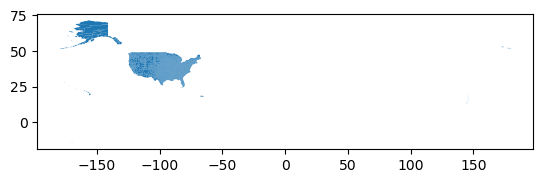

In [26]:
# d. Plot counties
counties.plot();

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.B. Cleaning

Simplify column names as needed.

In [27]:
# Transform column names to lowercawse
counties.columns = counties.columns.str.lower()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.C. Data selection

Select all the counties for the state of New York in a new variable `ny_counties` and plot them (you may need to look at the metadata).

In [28]:
# Select counties in New York state
ny_counties = counties[counties['statefp'] == '36'] # state FIPS code for NY from metadata = 36

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 7 Merging

The goal of this section is to create a single dataframe with the number of spills per county and the corresponding geometries for each county.

### 7.A. Explore data

In the next cells:

a. Print the names of counties in `ny_counties`, without repetition.


In [29]:
# Print names of NY counties
ny_county_names = ny_counties['name'].unique()
print(ny_county_names)

['Erie' 'Niagara' 'Jefferson' 'Steuben' 'Seneca' 'Rensselaer' 'Albany'
 'Saratoga' 'Schoharie' 'Schenectady' 'Ulster' 'Dutchess' 'Orange'
 'Columbia' 'Tompkins' 'Tioga' 'Broome' 'Cayuga' 'Genesee' 'Onondaga'
 'Oswego' 'Madison' 'Livingston' 'Monroe' 'Ontario' 'Orleans' 'Wayne'
 'Chautauqua' 'Sullivan' 'Chemung' 'Cattaraugus' 'Fulton' 'Montgomery'
 'Cortland' 'Warren' 'Washington' 'Otsego' 'Queens' 'Bronx' 'Nassau'
 'Westchester' 'Richmond' 'Kings' 'Suffolk' 'Rockland' 'New York' 'Putnam'
 'Clinton' 'St. Lawrence' 'Herkimer' 'Oneida' 'Yates' 'Greene' 'Schuyler'
 'Delaware' 'Hamilton' 'Lewis' 'Allegany' 'Chenango' 'Wyoming' 'Franklin'
 'Essex']


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Print the names of counties in `spills_per_county`, without repetition. Examine the differences in the outputs.

In [30]:
# Print county names from oil spill data
spills_county_names = spills_per_county['county'].unique()
print(spills_county_names)

['Albany' 'Allegany' 'Bronx' 'Broome' 'Cattaraugus' 'Cayuga' 'Chautauqua'
 'Chemung' 'Chenango' 'Clinton' 'Columbia' 'Cortland' 'Delaware'
 'Dutchess' 'Erie' 'Essex' 'Franklin' 'Fulton' 'Genesee' 'Greene'
 'Hamilton' 'Herkimer' 'Jefferson' 'Kings' 'Lewis' 'Livingston' 'Madison'
 'Monroe' 'Montgomery' 'Nassau' 'New Jersey - Region 2' 'New York'
 'Niagara' 'Oneida' 'Onondaga' 'Onondaga Indian Reservation' 'Ontario'
 'Orange' 'Orleans' 'Oswego' 'Otsego' 'Pennsylvania - Region 3' 'Putnam'
 'Queens' 'Rensselaer' 'Richmond' 'Rockland' 'Saratoga' 'Schenectady'
 'Schoharie' 'Schuyler' 'Seneca' 'St Lawrence' 'Steuben' 'Suffolk'
 'Sullivan' 'Tioga' 'Tompkins' 'Tuscarora Indian Reservation' 'Ulster'
 'Warren' 'Washington' 'Wayne' 'Westchester' 'Wyoming' 'Yates']


<!-- END QUESTION -->



c. Which are the county names that are in `spills_per_county`, but not in `ny_counties`? Your answer should be a list of strings
HINT: You can use the `numpy` function [`setdiff1d()`](https://numpy.org/doc/stable/reference/generated/numpy.setdiff1d.html), pay attention to the example in the documentation. Store your answer in the `diff_names` variable. 


In [31]:
diff_names_spills = np.setdiff1d(spills_county_names, ny_county_names)
print(diff_names_spills)

['New Jersey - Region 2' 'Onondaga Indian Reservation'
 'Pennsylvania - Region 3' 'St Lawrence' 'Tuscarora Indian Reservation']


In [32]:
grader.check("7Ac")

7Ac results: All test cases passed!

d. Which are the county names that are in `ny_counties`, but not in `spills_per_county`? Your answer should be a list of a string/strings.


In [33]:
diff_names_ny = np.setdiff1d(ny_county_names, spills_county_names)
print(diff_names_ny)

['St. Lawrence']


In [34]:
grader.check("7Ad")

7Ad results: All test cases passed!

e. What is the number of spills in 'Tuscarora Indian Reservation' and in 'Onondaga Indian Reservation'?


In [35]:
# e. Find number of spills in Tuscarora and Onodaga Indian Reservation
spills_per_county[(spills_per_county['county'] == 'Tuscarora Indian Reservation') | (spills_per_county['county'] == 'Onondaga Indian Reservation')]

,county,n_spills
35,Onondaga Indian Reservation,1
58,Tuscarora Indian Reservation,2


### 7.B. Data updates

In the next cell, update 'St Lawrence' to 'St. Lawrence' in the `spills_per_county` data frame. Verify the update was successful with an assert test. 


In [36]:
# Set 'St Lawrence' county to 'St. Lawrence'
# Check index of `St Lawrence`
spills_per_county[spills_per_county['county'] == 'St Lawrence']
spills_per_county.iloc[52,0] = 'St. Lawrence'

assert (spills_per_county.iloc[52,0] == 'St. Lawrence')

### 7.C. Merge

In the following cells:

a. Use this cell to make any other updates needed for making an inner join of the `spills_per_county` and `ny_counties`. HINT: [`pd.merge`](https://pandas.pydata.org/pandas-docs/version/2.3/reference/api/pandas.merge.html)


In [37]:
# a. Change column `name` to `county`
ny_counties = ny_counties.rename(columns={'name':'county'})

b. Store the inner join of the `spills_per_county` and `ny_counties` dataframes in a new variable named `ny_spills`.


In [38]:
# Combine spills per county with NY counties
ny_spills = ny_counties.merge(spills_per_county, on='county')
ny_spills.head()

,statefp,countyfp,countyns,geoid,geoidfq,county,namelsad,lsad,classfp,mtfcc,csafp,cbsafp,metdivfp,funcstat,aland,awater,intptlat,intptlon,geometry,n_spills
0,36,029,00974113,36029,0500000US36029,Erie,Erie County,06,H1,G4020,160,15380,None,A,2700743371,476876406,+42.7527590,-078.7781922,"POLYGON ((-78.77760 42.46188, -78.77756 42.461...",320
1,36,063,00974130,36063,0500000US36063,Niagara,Niagara County,06,H1,G4020,160,15380,None,A,1352876142,1598772310,+43.2726719,-078.8129431,"POLYGON ((-78.49165 43.08396, -78.49179 43.084...",97
2,36,045,00974121,36045,0500000US36045,Jefferson,Jefferson County,06,H1,G4020,None,48060,None,A,3283928401,1524534721,+43.9963890,-076.0529678,"POLYGON ((-75.90417 43.69796, -75.90437 43.697...",114
3,36,101,00974148,36101,0500000US36101,Steuben,Steuben County,06,H1,G4020,236,18500,None,A,3601403364,35034920,+42.2667252,-077.3855253,"POLYGON ((-77.08327 42.00002, -77.09391 41.999...",77
4,36,099,00974147,36099,0500000US36099,Seneca,Seneca County,06,H1,G4020,464,42900,None,A,838377561,172813845,+42.7822943,-076.8270880,"POLYGON ((-76.96393 43.01284, -76.96393 43.012...",27


<!-- BEGIN QUESTION -->

c. An inner join only keeps the rows whose `county` appears in both dataframes, and it does not warn you about the rows it drops. Which records from `spills_per_county` were dropped by the inner join, and how many spills did each one have? Add the cells you need to find the dropped records.

In [39]:
# Check number of spills for each county dropped in inner join
spills_per_county[~spills_per_county['county'].isin(ny_spills['county'])]

,county,n_spills
30,New Jersey - Region 2,7
35,Onondaga Indian Reservation,1
41,Pennsylvania - Region 3,1
58,Tuscarora Indian Reservation,2


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Does dropping these records affect the map or the information we will report? Write your answer in the following markdown cell.

Yes, while two of the counties are outside of NY, they may still impact neighboring NY counties. Their affects will not be recorded in this report. Additionally, dropping the Indian Reservation will reduce the number of reported spills in their associated NY county areas.

<!-- END QUESTION -->


From our previous exploration we know that Tuscarora Indian Reservation and Onondaga Indian Reservation will not be in the join. Tuscarora Indian Reservation is located within Niagara county and Onondaga Indian Reservation is located within Onondaga county. 

e. Since the reservations do not appear in the `ny_counties` dataframe, add the Tuscarora Indian Reservation spills to Niagara county and the Onondaga Indian Reservation spills to Onondaga county in `ny_spills`. We will add a note about this in our final map, and we will reflect on this choice in exercise 8.b. Add the cells you need to make this update **and** verify that the dataframe was updated.

In [40]:
# Check current Onondaga and Niagra County number of spills
ny_spills[(ny_spills['county'] == "Onondaga") | (ny_spills['county'] == "Niagara")][['county', 'n_spills']]

,county,n_spills
1,Niagara,97
19,Onondaga,214


In [41]:
# Add Tuscarora Indian Reserve spills to Niagra county count
ny_spills.at[1, 'n_spills'] = ny_spills.at[1, 'n_spills'] + spills_per_county.loc[58,'n_spills']

# Check row was updates
ny_spills[(ny_spills['county'] == "Niagara")][['county', 'n_spills']]

,county,n_spills
1,Niagara,99


In [42]:
# Add Onondaga Indian Reservation spill to Onondaga county count
ny_spills.at[19, 'n_spills'] = ny_spills.at[19, 'n_spills'] + spills_per_county.loc[35,'n_spills']

# Check row was updates
ny_spills[(ny_spills['county'] == "Onondaga")][['county', 'n_spills']]

,county,n_spills
19,Onondaga,215


## 8. Map
a. Create a choropleth map of the number of petroleum spills per county in the state of New York in 2023. 
Your map should be polished and have (at least) the following updates:
- a legend indicating the number of spills
- an updated color map
- a title 
- no axis
- an annotation with the data source (New York State Department of Environmental Conservation) and date of access



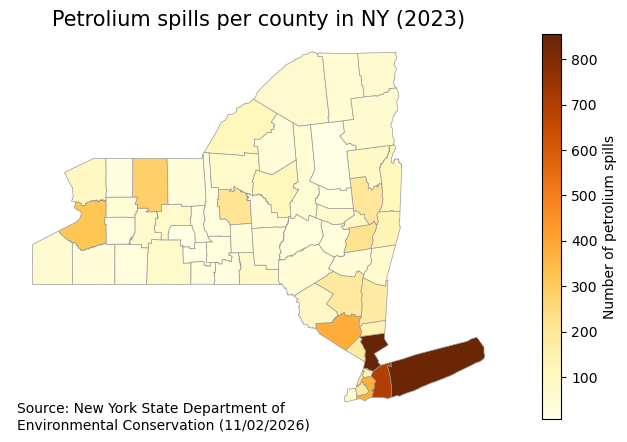

In [43]:
# Plot petrolium spills per county in NY
fig, ax = plt.subplots(figsize=(9, 5)) # Update figure size

# Remove the axis for a cleaner map
ax.axis('off')

# Title for the plot
ax.set_title('Petrolium spills per county in NY (2023)', 
              fontsize=15)

# Add oil spill by county
ny_spills.plot(ax=ax,
               column = 'n_spills',
               cmap = 'YlOrBr',
               edgecolor="0.6",
               linewidth=0.5,
               legend = True,
               legend_kwds={'label': 'Number of petrolium spills'}
              )

# Add caption
plt.figtext(0.2, 0.095,
            'Source: New York State Department of \nEnvironmental Conservation (11/02/2026)',
            horizontalalignment = 'left',
            wrap = True
           )
                  
plt.show()

b. Write a description of how the map was created, including key takeaways. If you need to do additional data analysis to include relevant information from the data, you may include additional cells here.

In your description, also reflect on how we handled the spills reported in the Tuscarora and Onondaga Indian Reservations (exercise 7.C.e) in terms of data governance and the CARE Principles for Indigenous Data Governance from Task 1.

This map was created with two datasets: New York State Department of Environmental Conservation's oil spill dataset, and the US Census Bureau's TIGER shapefiles of county borders. The number of petroleum spills in 2023 per county was calculated from the oil spill dataset. Note that one county entry from this dataset, `St Lawrence`, was manually renamed to `St. Lawrence` to match the TIGER shapefile data. The spills per county data were then merged with the TIGER county borders data to add the county geometries for mapping. The oil spill data lists the Tuscarora and Onondaga Indian Reservations as unique `county` values where spills occured, while the TIGER shapefiles do not include them specifically. Since these reservations are located within New York state, it was important to make sure this data was represented in our New York map and not excluded. To incorporate the data, it was decided to include the number of spills that occured in reseravtions to the total spill count of the counties they are located in. The two Tuscarora Reservation spills were added to `Niagra` county count and the single Onondaga Reservation spill was added to the `Onondaga` county count. Finally, the total counts were visualized using a choropleth map. From the map, one can see the vast majority of 2023 petroleum spills in NY occurred around Westchester county and Long Island.

## Complete workflow

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the choropleth map of the number of petroleum spills per county in the state of New York in 2023. The only output of this cell should be the choropleth map  you produced in the previous exercise. Further guidance on what to include in this final workflow is in the assignment rubric.